<a href="https://colab.research.google.com/github/DanielV-13/ADFM----PL_03_dense_vs_convolutional.ipynb/blob/main/ADFM_PL_03_dense_vs_convolutional.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis de Datos en Física Moderna
## Pietro Vischia (Universidad de Oviedo and ICTEA), pietro.vischia@cern.ch

The core of this tutorial comes from https://github.com/vischia/data_science_school_igfae2024 (Pietro Vischia (pietro.vischia@cern.ch)).

# Metodología y Diseño Experimental: Redes Densas (MLP) vs. Redes Convolucionales (CNN) en MNIST

**- MULTI-LAYER PERCEPTON  y CONVOLUTIONAL NEURAL NETWORK**

El objetivo de este cuaderno es realizar un análisis comparativo riguroso entre dos paradigmas fundamentales del aprendizaje profundo: las **Redes Neuronales Totalmente Conectadas (Perceptrón Multicapa o MLP)** y las **Redes Neuronales Convolucionales (CNN)**. A través de una exploración sistemática de hiperparámetros, arquitecturas y funciones de pérdida, conectaremos la formulación matemática con el comportamiento empírico durante el entrenamiento sobre el conjunto de datos **MNIST** (imágenes en escala de grises de $28 \times 28$ píxeles distribuidas en 10 clases correspondientes a los dígitos del $0$ al $9$).

---

## 1. Preprocesamiento y Estandarización de Datos
Antes de alimentar cualquier arquitectura neuronal, el espacio de características de entrada $X \in \mathbb{R}^{N \times 1 \times 28 \times 28}$ debe ser acondicionado matemáticamente para estabilizar el flujo de gradientes:

* **Reescalado Lineal (`ToTensor`):** Transforma los valores enteros originales de intensidad de píxel $[0, 255]$ al intervalo continuo $[0.0, 1.0]$. Esto evita saturaciones inmediatas en las activaciones iniciales.
* **Estandarización Z-score (`Normalize`):** Transforma cada píxel $x_{i,j}$ restando la media global ($\mu = 0.1307$) y dividiendo por la desviación estándar ($\sigma = 0.3081$) del conjunto MNIST:
  $$x'_{i,j} = \frac{x_{i,j} - \mu}{\sigma}$$
  *Justificación teórica:* Centrar los datos alrededor de cero con varianza unitaria garantiza que la superficie de la función de pérdida sea más isotrópica (esférica en lugar de elíptica alargada). Esto evita oscilaciones erráticas durante el descenso de gradiente y acelera drásticamente la convergencia de optimizadores adaptativos como **Adam**.

---

## 2. Arquitectura Densa (*Fully Connected* / MLP MULTI LAYER PERCEPTON)
En una red densa, la estructura bidimensional de la imagen se destruye mediante una operación de aplanamiento (*flattening*), proyectando la matriz $28 \times 28$ en un vector unidimensional $\mathbf{x} \in \mathbb{R}^{784}$.

* **Topología y Profundidad:** Definiremos bloques secuenciales compuestos por transformaciones afines $\mathbf{z}^{(l)} = \mathbf{W}^{(l)}\mathbf{a}^{(l-1)} + \mathbf{b}^{(l)}$ seguidas de no linealidades **ReLU**, $\sigma(z) = \max(0, z)$, para evitar el desvanecimiento del gradiente (*vanishing gradient*) presente en funciones como la sigmoide.
* **Criterio de Dimensionamiento y Explosión de Parámetros:** En una red densa de arquitectura $784 \to 128 \to 64 \to 10$, el número total de parámetros entrenables asciende a:
  $$N_{\text{params}} = (784 \times 128 + 128) + (128 \times 64 + 64) + (64 \times 10 + 10) = 109,386$$
  *Limitación física y geométrica:* El MLP carece de **invarianza traslacional** y no explota la correlación espacial local. Cada píxel es tratado como una variable independiente; si un dígito se desplaza apenas dos píxeles hacia la derecha, la red densa debe reaprender los pesos desde cero para esa nueva posición.

---

## 3. Arquitectura Convolucional (CNN)
Las CNN resuelven la ineficiencia de las redes densas introduciendo dos sesgos inductivos fundamentales inspirados en la corteza visual y en los operadores diferenciales de la física: **conectividad local** y **compartición de pesos (*weight sharing*)**.

* **Operación de Convolución Discreta (`Conv2d`):** Un filtro o *kernel* $\mathbf{K} \in \mathbb{R}^{k \times k}$ se desliza sobre la imagen calculando productos internos locales:
  $$(I * K)(i, j) = \sum_{m=0}^{k-1} \sum_{n=0}^{k-1} I(i + m, j + n) \cdot K(m, n)$$
  *Analogía con Física de Partículas (Señal vs. Fondo):* Cada filtro actúa como un detector especializado de patrones locales (bordes verticales, curvas, trazos diagonales). Las regiones de la imagen que coinciden con la morfología del filtro generan una activación intensa (**Señal**), mientras que el espacio vacío o irrelevante es suprimido a valores cercanos a cero (**Fondo**).
* **Estudio Comparativo de Kernels ($k \times k$):** Evaluaremos cómo el tamaño del campo receptivo afecta la extracción de características:
  * **Kernels pequeños ($3 \times 3$):** Capturan detalles locales muy finos con un costo computacional bajo ($9$ parámetros por canal). Al apilar múltiples capas de $3 \times 3$, se logra un campo receptivo efectivo equivalente a filtros más grandes pero con mayor no linealidad y menor número de parámetros.
  * **Kernels medianos/grandes ($5 \times 5$ o $7 \times 7$):** Abarcan un contexto espacial más amplio en una sola capa ($25$ a $49$ parámetros por canal), pero incrementan el costo cuadrático de operaciones por ventana y tienden a suavizar detalles de alta frecuencia.
* **Control Espacial (`Padding` y `Stride`) y Submuestreo (`MaxPool2d`):** Utilizaremos *padding* para preservar las dimensiones en los bordes de la imagen y capas de `MaxPool2d` ($2 \times 2$, *stride* $2$) para reducir la resolución espacial a la mitad en cada etapa ($28 \times 28 \to 14 \times 14 \to 7 \times 7$), otorgando invarianza local ante pequeñas distorsiones y reduciendo la carga computacional antes del clasificador denso final.

---

## 4. Dinámica de Entrenamiento y Eficiencia Computacional
El rendimiento de una arquitectura no solo se mide por su precisión final, sino por su eficiencia temporal y estabilidad numérica:

* **Rapidez de Entrenamiento y Complejidad Computacional:** Aunque una CNN tiene **significativamente menos parámetros entrenables** que un MLP (a menudo entre $5\times$ y $10\times$ menos), requiere un mayor número de operaciones de punto flotante (**FLOPs**) por pasada hacia adelante (*forward pass*) debido a que cada filtro recorre espacialmente toda la matriz de entrada. Compararemos empíricamente el tiempo de ejecución por época (`wall-clock time`) frente a la velocidad de convergencia por iteración.
* **Esquema de Optimización y Planificación (`Adam` + `ExponentialLR`):** Evaluaremos el impacto del tamaño de lote (*batch size*) en la varianza del gradiente estocástico y utilizaremos decaimiento exponencial de la tasa de aprendizaje ($\eta_t = \eta_0 \cdot \gamma^t$) para realizar ajustes finos en el mínimo de la función de costo durante las últimas épocas.

---

## 5. Funciones de Pérdida y Evaluación de Desempeño
* **Entropía Cruzada Multiclase (`CrossEntropyLoss`):** Combina internamente una activación **Log-Softmax** sobre los *logits* crudos de salida $\mathbf{z} \in \mathbb{R}^{10}$ con la pérdida de verosimilitud logarítmica negativa (*Negative Log-Likelihood*):
  $$\mathcal{L}(\mathbf{z}, y) = -\log\left(\frac{e^{z_y}}{\sum_{j=0}^{9} e^{z_j}}\right) = -z_y + \log\left(\sum_{j=0}^{9} e^{z_j}\right)$$
  *Criterio matemático:* Penaliza logarítmicamente las predicciones seguras pero erróneas, generando gradientes limpios y proporcionales al error ($\frac{\partial \mathcal{L}}{\partial z_i} = p_i - y_i$) sin requerir una capa `Softmax` explícita al final del modelo.
* **Métricas Continuas vs. Discretizadas:**
  * Analizaremos la evolución continua de la **función de pérdida** (capacidad de calibración probabilística y detección temprana de sobreajuste o *overfitting* cuando la pérdida de validación diverge respecto a la de entrenamiento).
  * Contrastaremos esto con métricas discretizadas mediante el operador $\arg\max$: la **Exactitud Global (*Accuracy*)** y la **Matriz de Confusión** ($10 \times 10$), identificando qué pares de dígitos presentan mayor solapamiento morfológico (ej. confundir un `4` con un `9`, o un `3` con un `8`).

In [7]:
# ==========================================
# 1. IMPORTACIÓN DE LIBRERÍAS DE DEEP LEARNING
# ==========================================

import torch       # Framework central de PyTorch para cálculo tensorial y autograd
import torch
import torch.nn as nn   # Módulo de redes neuronales (capas, funciones de pérdida, contenedores secuenciales)
import torch.optim as optim  # Algoritmos de optimización (Adam, SGD, etc.) para actualización de pesos
import torch.nn.functional as F    # Funciones operacionales sin estado (activaciones, pooling funcional)
from torch.utils.data import DataLoader  # Gestor para cargar lotes de datos (batching) y barajarlos (shuffling)
import torchvision          # Librería auxiliar con datasets estándar (MNIST) y transformaciones de imagen
from tqdm import tqdm     # Utilidad para mostrar barras de progreso interactivas en bucles de entrenamiento


# ==========================================
# 2. LIBRERÍAS DE VISUALIZACIÓN Y CÁLCULO NUMÉRICO
# ==========================================
import matplotlib    # Librería base para la generación de gráficos
%matplotlib inline
# Comando mágico para renderizar las gráficas directamente dentro del entorno de Colab

import matplotlib.pyplot as plt  # Interfaz de Pyplot para trazar curvas de pérdida, precisión y matrices de confusión
import numpy as np       # Librería fundamental para manipulación eficiente de matrices y operaciones numéricas



# ==========================================
# 3. CONFIGURACIÓN DEL HARDWARE DE EJECUCIÓN
# ==========================================
# Detecta automáticamente si hay una GPU NVIDIA disponible (CUDA).
# Si existe, asigna el cálculo a la tarjeta gráfica para acelerar masivamente el entrenamiento;
# de lo contrario, recurre de forma segura al procesador principal (CPU).
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

---

## Preparación y Transformación del Dataset MNIST

Antes de entrenar cualquier modelo de aprendizaje profundo, las imágenes crudas de entrada deben pasar por una **tubería de preprocesamiento (*pipeline*)** para acondicionar su representación numérica. Esto estabiliza la propagación de gradientes y acelera la convergencia de la optimización.

### 1. El Objeto `torchvision.transforms.Compose`
Permite encadenar múltiples transformaciones de manera secuencial. Cada imagen del dataset fluye a través de esta tubería antes de ser entregada al modelo.

### 2. Conversión a Tensor (`ToTensor`)
* **Qué hace:** Convierte una imagen de tipo PIL (Python Imaging Library) o un arreglo de NumPy con valores enteros de $0$ a $255$ en un **tensor flotante de PyTorch** ($\in \mathbb{R}^{C \times H \times W}$).
* **Efecto matemático:** Recala automáticamente los valores de intensidad dividiendo por $255$, proyectándolos al rango continuo de probabilidad $[0.0, 1.0]$:
  $$x_{\text{tensor}} = \frac{x_{\text{pixel}}}{255}$$

### 3. Estandarización Estadística (`Normalize`)
* **Qué hace:** Aplica una transformación de puntuación Z (*Z-score standardization*) utilizando la media global ($\mu$) y la desviación estándar ($\sigma$) precalculadas de todo el conjunto de datos MNIST:
  $$x_{\text{norm}} = \frac{x_{\text{tensor}} - \mu}{\sigma}$$
* **Valores específicos de MNIST:**
  * **Media ($\mu$):** `0.1307`
  * **Desviación Estándar ($\sigma$):** `0.3081`
* **Justificación técnica y pedagógica:**
  Centrar los datos alrededor de cero con varianza unitaria evita que la superficie de la función de pérdida presente desniveles extremos o valles muy alargados (elongados). Esto previene oscilaciones erráticas en el descenso de gradiente y permite utilizar tasas de aprendizaje más estables.
  
> **Nota experimental sugerida:** El cuaderno recomienda **empezar sin aplicar la normalización** (es decir, trabajando únicamente con el reescalado a $[0, 1]$ de `ToTensor`) para evaluar empíricamente cómo cambia la velocidad de aprendizaje y el comportamiento de la pérdida frente al modelo estandarizado.

---

Load the MNIST dataset and inspect it.
This dataset is handily hosted in the package `torchvision`.

You can also apply a series of transformations, e.g. the following if you want to standardize automatically the dataset to the global mean and variance. Suggestion: start by not standardizing.

NOTE: the standardization transform is called `normalize` in the package `torchvision`.

```
transform=torchvision.transforms.Compose([
                               torchvision.transforms.ToTensor(),
                               torchvision.transforms.Normalize(
                                 (0.1307,), (0.3081,))
                             ]))
```

Another transform it is usually done is to divide values in the image by `255` to have them before 0 and 1.

---
## Carga y Gestión de Lotes de Datos (*Data Loading & Batching*)

Una vez definidas las transformaciones, procedemos a descargar, instanciar y empaquetar el conjunto de datos MNIST utilizando las utilidades de `torchvision` y PyTorch.

### 1. Descarga e Instanciación de Datasets
* **`torchvision.datasets.MNIST`:** Descarga automáticamente el repositorio oficial de imágenes de dígitos si no se encuentra localmente en la ruta especificada (`root='dataset/'`).
* **Separación de Datos:**
  * `train=True`: Carga el conjunto de entrenamiento compuesto por $60,000$ muestras.
  * `train=False`: Carga el conjunto de prueba (*test*) compuesto por $10,000$ muestras independientes para evaluar la generalización del modelo.

### 2. El Gestor de Lotes (`DataLoader`)
El entrenamiento moderno mediante Descenso de Gradiente Estocástico (SGD) o sus variantes (como Adam) no procesa las imágenes una por una ni todas juntas de golpe, sino divididas en **lotes (*batches*)**:
* **`batch_size = 64`:** Agrupa $64$ imágenes y sus respectivas etiquetas en un solo tensor multidimensional por iteración. Esto optimiza el uso de la memoria de la GPU y estabiliza la estimación del gradiente.
* **`shuffle=True` (en entrenamiento):** Baraja aleatoriamente el orden de las muestras en cada época. Esto es fundamental para romper correlaciones espaciales o temporales y evitar que el modelo memorice el orden de los datos.
* **`shuffle=True` (en prueba, opcional):** Aunque en el conjunto de test el orden no afecta el cálculo final de la pérdida o precisión, mantenerlo activo o inactivo es parte de la flexibilidad del script.

---

In [9]:
# ==========================================
# 1. CONFIGURACIÓN DE HIPERPARÁMETROS DE CARGA
# ==========================================
batch_size = 64 # Or whichever value you may see fit
# You can also explore whether dense and convolutional networks work best with different batch sizes

# Tamaño del lote: número de muestras procesadas simultáneamente por iteración.
                 # Nota: Puedes experimentar si las redes densas y convolucionales se benefician
                 # de tamaños de lote diferentes (ej. 32, 64, 128, 256).



# Load Data
# ==========================================
# 2. CARGA DEL CONJUNTO DE ENTRENAMIENTO (TRAIN)
# ==========================================
# Descarga (si es necesario) y carga el dataset de entrenamiento MNIST desde torchvision.

train_dataset = torchvision.datasets.MNIST(
                                          root='dataset/',    # Directorio local donde se almacenarán los archivos descargados
                                           train=True,       # Selecciona la partición de entrenamiento (60,000 muestras)
                                           transform=torchvision.transforms.ToTensor(),  # Aplica la conversión a tensor y reescalado a [0.0, 1.0]
                                           #target_transform = torchvision.transforms.Compose([
                                           # lambda x:torch.LongTensor([x]), # or just torch.tensor
                                           # lambda x:F.one_hot(x,10)]),
                                            download=True)   # Descarga automática si la carpeta está vacía




# El DataLoader envuelve el dataset para proveer iteración por lotes y barajado automático (shuffling)
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size,
                          shuffle=True)  # Baraja los datos al inicio de cada época para evitar sesgos de orden



# ==========================================
# 3. CARGA DEL CONJUNTO DE PRUEBA (TEST / VALIDACIÓN)
# ==========================================
# Descarga y carga el dataset de prueba MNIST para evaluar el rendimiento fuera de muestra.

test_dataset = torchvision.datasets.MNIST(
                                          root='dataset/',   # Mismo directorio base
                                          train=False,     # Selecciona la partición de prueba (10,000 muestras)
                                          transform=torchvision.transforms.ToTensor(),  # Aplica la misma transformación base

#target_transform = torchvision.transforms.Compose([
#                                 lambda x:torch.LongTensor([x]), # or just torch.tensor
#                                 lambda x:F.one_hot(x,10)]),
                                          download=True)  # Asegura la disponibilidad de los datos


# Gestor de lotes para el conjunto de prueba
test_loader = DataLoader(dataset=test_dataset,
                         batch_size=batch_size,
                         shuffle=True) # Mezcla los datos de prueba (también puede configurarse en False si se prefiere orden secuencial)

---

## Inspección Visual del Dataset

Antes de alimentar los datos a una red neuronal, es una buena práctica de ingeniería y rigor científico inspeccionar visualmente las muestras para verificar la integridad del pipeline de carga.

### 1. Extracción de un Lote de Prueba (`DataLoader` e Iteradores)
* Convertimos el `test_loader` en un objeto iterable mediante la función `enumerate` y extraemos el primer lote utilizando `next()`.
* Esto nos entrega un par de tensores:
  * `example_data`: Contiene las imágenes en formato tensor con dimensiones tipicas de PyTorch `[Batch_Size, Canales, Alto, Ancho]` (es decir, `[64, 1, 28, 28]`).
  * `example_targets`: Contiene las etiquetas correspondientes a cada imagen.

### 2. Generación de una Cuadrícula de Visualización (`Matplotlib`)
* Utilizamos un bucle `for` para iterar sobre las primeras $6$ imágenes del lote y organizarlas en una malla de $2 \times 3$ subgráficos (`plt.subplot(2, 3, i + 1)`).
* **Representación de la Imagen:** Mediante `plt.imshow` extraemos el canal único (`example_data[i][0]`) aplicando una paleta de grises (`cmap='gray'`) para renderizar correctamente los píxeles.
* **Etiquetado Real (*Ground Truth*):** Usamos `torch.argmax` sobre la etiqueta objetivo para extraer el valor numérico real del dígito y mostrarlo como título de cada subgráfico.
* **Limpieza Visual:** Se suprimen los ejes numéricos (`plt.xticks([])`, `plt.yticks([])`) para enfocar la atención puramente en la morfología de la imagen del dígito.

---

We can inspect the dataset.

Suggestion: inspect the dataset after trying out different transforms.

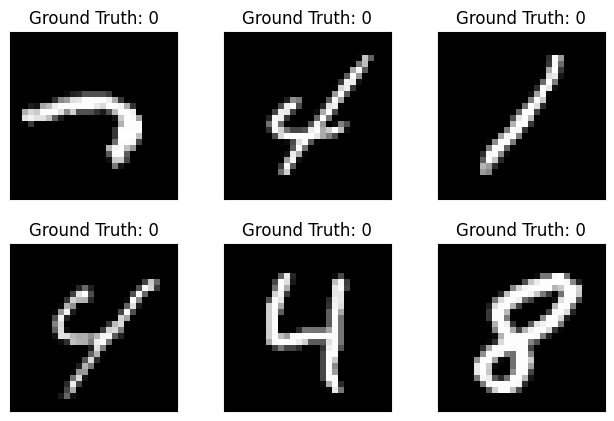

In [15]:

# ==========================================
# 1. EXTRACCIÓN DE UN LOTE DESDE EL DATALOADER
# ==========================================
# Convierte el test_loader en un iterador para extraer su contenido de forma manual
examples = enumerate(test_loader)

# Obtiene el índice del lote y desempaca el primer lote de datos compuesto por:
# - example_data: Tensor con las imágenes (dimensiones: [64, 1, 28, 28])
# - example_targets: Tensor con las etiquetas correspondientes a cada imagen
batch_idx, (example_data, example_targets) = next(examples)

# Imprime las dimensiones del tensor de datos para verificar su estructura espacial y canales
example_data.shape

# Importación de la interfaz de trazado de Matplotlib
import matplotlib.pyplot as plt


# ==========================================
# 2. VISUALIZACIÓN DE LAS PRIMERAS 6 MUESTRAS
# ==========================================
# Inicializa una nueva figura para contener la visualización
fig = plt.figure()

# Bucle para recorrer y graficar los primeros 6 elementos del lote actual
for i in range(6):
  # Crea una cuadrícula de subgráficos de 2 filas por 3 columnas, posicionándose en el índice i+1
  plt.subplot(2,3,i+1)

  # Ajusta automáticamente los espacios y márgenes entre los subgráficos
  plt.tight_layout()

  # Muestra la imagen: toma la i-ésima muestra y su único canal (índice 0),
  # aplicando escala de grises y desactivando la interpolación para ver los píxeles nítidos
  plt.imshow(example_data[i][0], cmap='gray', interpolation='none')

  # Asigna como título el valor real de la etiqueta ("Ground Truth") obtenido mediante torch.argmax
  plt.title("Ground Truth: {}".format(torch.argmax(example_targets[i])))

  # Elimina las marcas numéricas del eje X e Y para una presentación más limpia
  plt.xticks([])
  plt.yticks([])


---

## Pregunta Frecuente: ¿Por qué cambian las imágenes mostradas con cada ejecución?

Al ejecutar repetidamente la celda de inspección visual, es completamente normal notar que los dígitos mostrados cambian en cada intento. Esto responde a la lógica de carga y aleatoriedad del modelo:

### 1. El parámetro de barajado (`shuffle=True`)
* Al definir el `DataLoader` (tanto para entrenamiento como para prueba), configuramos `shuffle=True`. Esto ordena a PyTorch reorganizar y mezclar de forma completamente aleatoria el orden de las muestras en cada ciclo.

### 2. La extracción del iterador (`next(examples)`)
* Cada vez que se presiona "Play" en la celda, se instancia un nuevo iterador mediante `enumerate(test_loader)` y se extrae el primer lote con `next(examples)`.
* Como los datos están barajados, el "primer lote" devuelto contendrá un subconjunto de imágenes totalmente distinto al de la ejecución anterior. Esto es una práctica fundamental en machine learning para garantizar la robustez y evitar cualquier sesgo asociado al orden estático de los datos.

---

---

# Definición del Modelo de Red Neuronal Densa (`DenseNetwork`)

En esta sección construimos la arquitectura de una **Red Neuronal Totalmente Conectada** (también conocida como Perceptrón Multicapa o MLP) heredando directamente de la clase base `nn.Module` de PyTorch.

### 1. Estructura de la Clase y el Constructor (`__init__`)
* **Herencia de `nn.Module`:** Toda red neuronal personalizada en PyTorch debe heredar de `nn.Module` para registrar automáticamente los pesos, sesgos, gradientes y métodos de optimización.
* **Contenedor Secuencial (`nn.Sequential`):** Agrupa las capas de forma lineal y ordenada, facilitando que la salida de una operación pase automáticamente como entrada a la siguiente.
* **Capas Lineales (`nn.Linear`) y No Lineales (`nn.ReLU`):**
  * La red recibe un vector de entrada aplanado de tamaño `input_size` (para MNIST, $28 \times 28 = 784$ píxeles) y lo proyecta a una primera capa oculta de $128$ neuronas.
  * Se aplica una función de activación **ReLU** ($\max(0, x)$) para dotar al modelo de la no linealidad necesaria para aprender patrones complejos.
  * Una segunda capa oculta comprime la representación de $128$ a $64$ neuronas, seguida de otra activación **ReLU**.
  * Finalmente, la capa de salida proyecta las $64$ características hacia el número total de clases (`num_classes = 10`), generando los *logits* para cada dígito.
* **Opciones Alternativas Comentadas:** El código incluye ejemplos de otras capas comunes que se pueden explorar, como `nn.Dropout` (para apagar neuronas aleatoriamente y prevenir sobreajuste), `nn.BatchNorm1d` (para normalizar las activaciones intermedias) o funciones de activación como sigmoide y *Softmax*.
* **Asignación al Dispositivo:** Con `self.dense.to(device)` garantizamos que todos los tensores de parámetros del modelo sean enviados al hardware configurado (GPU o CPU).

### 2. Propagación hacia Adelante (`forward`)
* Define el flujo computacional de la red cuando procesa un lote de datos de entrada `x`.
* Pasa el tensor a través de la secuencia de capas definidas en `self.dense(x)` y retorna el resultado de la predicción.

---

Define a fully connected neural network model


In [ ]:
class DenseNetwork(nn.Module):
    def __init__(self, input_size, num_classes, device=torch.device("cpu")):
        super().__init__()
        self.dense = nn.Sequential(
            # here put layers. Some choices you have seen are:
            #     nn.Dropout(p=0.4),
            #     nn.Linear(input_size, 128),
            #     nn.BatchNorm1d(128),
            #     nn.ReLU(),
            #     nn.sigmoid(),
            #     nn.Softmax(dim=1)
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes),
        )
        self.dense.to(device)

    def forward(self, x):
        x = self.dense(x)
        return x


In [ ]:
input_size = 28*28*1 # You have to figure this out
num_classes = 10 # You have to figure this out
learning_rate = 0.001 # You have to figure this out
num_epochs = 3 # You have to figure this out

# Initialize Network
model = DenseNetwork(input_size=input_size, num_classes=num_classes).to(device)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters()), sum(p.numel() for p in model.parameters() if p.requires_grad)

total_pars, trainable_pars = count_parameters(model)
print("I have ", total_pars, "parameter and ", trainable_pars, " trainable parameters")

print("len", len([i for i in model.parameters()]))
# Loss and Optimizer
loss_fn = torch.nn.CrossEntropyLoss() # You have to figure this out
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.9)

I have  109386 parameter and  109386  trainable parameters
len 6


The transformation `torchvision.transforms.Normalize` does what we call *Standardizatio*, that is it rescales data to have the same mean and variance. Here, the two hardcoded values are the mean and variance of the whole MNIST data set.


In [ ]:
def train_loop(dataloader, model, loss_fn, optimizer, scheduler, cnn, device):
    losses=[] # Track the loss function
    accs= [] # Track accuracies

    # Set the model to training mode - important for batch normalization and dropout layers
    # Unnecessary in this situation but added for best practices
    model.train()
    for batch, (X, y) in enumerate(dataloader):
    #for batch, (X, y) in tqdm(enumerate(dataloader, 0), unit="batch", total=len(dataloader)):
    #for (X,y) in tqdm(dataloader):
        # Reset gradients (to avoid their accumulation)
        optimizer.zero_grad()
        # Compute prediction and loss
        if not cnn:
            X = X.reshape(X.shape[0], -1)
        pred = model(X)

        #print("Y", y)
        #pred= pred.reshape([pred.shape[0], 1, num_classes])
        #print(torch.argmax(pred, dim=2), torch.argmax(y, dim=2))
        loss = loss_fn(pred,y)
        #print(loss)
        losses.append(loss.detach().cpu())
        acc = (torch.argmax(pred, 1) == y).float().mean()
        accs.append(acc.detach().cpu())
        loss.backward()
        optimizer.step()

    return np.mean(losses), np.mean(accs)

def test_loop(dataloader, model, loss_fn, cnn, device):

    losses=[] # Track the loss function
    accs = [] # Track accuracies
    # Set the model to evaluation mode - important for batch normalization and dropout layers
    # Unnecessary in this situation but added for best practices
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    # Evaluating the model with torch.no_grad() ensures that no gradients are computed during test mode
    # also serves to reduce unnecessary gradient computations and memory usage for tensors with requires_grad=True
    with torch.no_grad():
        #for batch, (X, y) in tqdm(enumerate(dataloader, 0), unit="batch", total=len(dataloader)):
        for (X,y) in tqdm(dataloader):
            if not cnn:
                X = X.reshape(X.shape[0], -1)
            pred = model(X)
            #pred= pred.reshape([pred.shape[0], 1, num_classes])
            loss = loss_fn(pred, y)
            acc = (torch.argmax(pred, 1) == y).float().mean()
            losses.append(loss)
            accs.append(acc.detach().cpu())
            test_loss += loss
            #correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    return np.mean(losses), np.mean(accs)


In [ ]:
train_losses=[]
test_losses=[]
train_accuracies=[]
test_accuracies=[]
for t in range(num_epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loss, train_accuracy = train_loop(train_loader, model, loss_fn, optimizer, scheduler, False, device)
    test_loss, test_accuracy = test_loop(test_loader, model, loss_fn, False, device)
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)
    print("Avg train loss", train_loss, ", Avg test loss", test_loss, "Current learning rate", scheduler.get_last_lr())
print("Done!")

Now let's create a convolutional network

Relevant parameters:

- `in_channels`: number of input channels. For black-and-white images, this is 1. RGB images have 3.
- `num_classes`: how many digits do we want to recognize?

The first `Conv2d` layer has 8 kernels of size 3x3, i.e. splits the image in eight separate channels each with its own convolution operation. Padding ensures the size of the image remains the same.
The second `Conv2d` layer has 16 filters, also with 3x3 kernel.

The `MaxPool2d` layer has a 2x2 kernel and a stride of 2. This does averaging and dimensional reduction, downsampling the image by a factor 2 in each dimension (from 28x28 to 14x14 the first time we apply it, and from 14x14 to 7x7 the second time).

The output of the second `Conv2d` layer will therefore a 16-channel image where each channel is 7x7. We flatten it to a one-dimensional vector per image to feed it to a dense layer that does classification.


In [ ]:
class ConvNetwork(nn.Module):
    def __init__(self, in_channels=1, num_classes=10):
        super(ConvNetwork, self).__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2)),
            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2)),
            nn.Flatten(),
            nn.Linear(16*7*7, num_classes)
            # Another activation function here? Or not?
        )
    def forward(self, x):
        x = self.conv(x)
        return x




Now we change the input parameters accordingly (in general they won't be the same as the dense network) and instatiate the convolutional network

In [ ]:
in_channels = 1 # You have to figure this out
num_classes = 10 # You have to figure this out
learning_rate = 0.01 # You have to figure this out
num_epochs = 5 # You have to figure this out

# Initialize Network
model = ConvNetwork(in_channels=in_channels, num_classes=num_classes).to(device)

# Loss and Optimizer
criterion = torch.nn.CrossEntropyLoss() # You have to figure this out
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

Now you can train again. The training and test look will be the same, but you will need to change the names in the loop below to save the training data for the convolutional network


In [ ]:
conv_train_losses=[]
conv_test_losses=[]
conv_train_accuracies=[]
conv_test_accuracies=[]
for t in range(num_epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    conv_train_loss, conv_train_accuracy = train_loop(train_loader, model, loss_fn, optimizer, scheduler, True, device)
    conv_test_loss, conv_test_accuracy = test_loop(test_loader, model, loss_fn, True, device)
    conv_train_losses.append(conv_train_loss)
    conv_train_accuracies.append(conv_train_accuracy)
    conv_test_losses.append(conv_test_loss)
    conv_test_accuracies.append(conv_test_accuracy)
    print("Avg train loss", conv_train_loss, ", Avg test loss", conv_test_loss, "Current learning rate", scheduler.get_last_lr())
print("Done!")

Now you can for instance plot the losses for both networks (train and test data sets), build the confusion matrix for the two networks, check how many trainable parameters (remember `torchinfo.summary(model)`...) are needed for each network type to give you a certain performance, and other useful stuff for the report